# Trabalho M2.2 — Filtragem, segmentação e morfologia

Gustavo Corrêa de Mello, Heloisa Cavalcante Born e João Paulo Jorge Aimi.

**Parte 1:** filtragem, Watershed, SLIC e comparação. **Parte 2:** limiarização, morfologia, preenchimento de buracos e contagem própria nas duas imagens do enunciado.

Executar do início ao fim. A imagem e a pasta de saída são definidas na seção de filtragem; a segmentação utiliza os mesmos arrays, sem gerar novo ruído.


# M2.2 — Filtragem na frequência

**Responsável: Heloisa Cavalcante Born** · Grupo: Gustavo Corrêa de Mello e João Paulo Jorge Aimi.

Imagem `2009_003974.jpg` do VOC2012 (`car_04` na galeria), RGB 500 × 335, conjunto Main/train. A cópia original não contém caixas. Fonte, SHA-256 e justificativa em `data/README.md`.

Este notebook executa apenas a frente de filtragem. Watershed/SLIC e células pertencem às outras frentes.


In [1]:
from pathlib import Path
import os
import subprocess
import sys

REPOSITORIO = "https://github.com/HeloisaBorn/trabalho-m2.2-pdi"
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None and "google.colab" in sys.modules:
    # O Colab abre só o .ipynb; clonamos o repositório para ter src/, scripts/ e tests/.
    ROOT = Path("/content/trabalho-m2.2-pdi")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORIO, str(ROOT)], check=True)
    os.chdir(ROOT)
if ROOT is None:
    raise RuntimeError("Abra o notebook dentro da pasta do projeto ou pelo link do Colab.")
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
# As imagens não ficam no git: o script baixa as que faltam e confere o SHA-256 de todas.
r = subprocess.run([sys.executable, str(ROOT / "scripts" / "baixar_dados.py")], capture_output=True, text=True)
print(r.stdout, r.stderr)
r.check_returncode()
from scripts.experimento_frequencia import executar
from IPython.display import display, Image, Markdown
import numpy as np

## 1. Modelo de ruído e plano experimental

Usamos $I_r=\operatorname{clip}(I+\eta,0,1)$, com $\eta\sim N(0,0{,}08^2)$, independente por canal; seed 42. A imagem limpa fica reservada como referência. O clipping torna o ruído efetivo não exatamente gaussiano perto dos extremos.

Comparamos máscaras Gaussianas e Butterworth de ordem 2 em uma grade fixa de 11 valores de corte, sem mudar o ruído entre execuções. As imagens não são redimensionadas. O padding refletido de 32 pixels reduz a descontinuidade artificial nas bordas da extensão periódica da FFT.


## 2. Filtros, transformada inversa e métricas

Para cada canal, calculamos $F=\operatorname{fftshift}(\operatorname{FFT2}(I_r))$, $G=HF$ e $I_f=\Re\{\operatorname{IFFT2}(\operatorname{ifftshift}(G))\}$. Depois, recortamos o padding e limitamos em [0,1], sem normalização por mínimo/máximo.

Com $D$ em ciclos/pixel, $H_G=\exp[-D^2/(2D_0^2)]$ e $H_B=[1+(D/D_0)^{2n}]^{-1}$. O mesmo $D_0$ não representa ganho idêntico entre as famílias: $H_G(D_0)\approx0{,}607$ e $H_B(D_0)=0{,}5$.

$MSE=\frac1N\sum (I-I_f)^2$ e $PSNR=10\log_{10}(1/MSE)$ para intervalo [0,1]. Média sobre todos os pixels e canais. PSNR é qualidade de restauração, não qualidade semântica de segmentação. SSIM é opcional no enunciado e não foi incluído nesta frente.

As máscaras, o ruído e as métricas são próprios; NumPy fornece somente operações numéricas e FFT. Não usamos filtros prontos.


In [2]:
# Para outra imagem, trocar CAMINHO_IMAGEM e escolher outra pasta de saída.
CAMINHO_IMAGEM = ROOT / "data/originais/2009_003974.jpg"
SAIDA = ROOT / "resultados/frequencia"
manifesto, tabela = executar(CAMINHO_IMAGEM, SAIDA, sigma=0.08, seed=42)
print("Imagem:", manifesto["imagem"], "Formato:", manifesto["shape"])
print("PSNR ruidosa:", round(manifesto["psnr_ruidosa_db"], 4), "dB")
print("Melhor configuração na grade:", manifesto["escolha"])


Imagem: 2009_003974.jpg Formato: [335, 500, 3]
PSNR ruidosa: 22.6133 dB
Melhor configuração na grade: {'filtro': 'gaussiano', 'corte': 0.25, 'ordem': '', 'mse': 0.0024442264447737537, 'psnr_db': 26.118585614572897, 'ganho_db': 3.505264161989871}


## 3. Comparação quantitativa — todas as configurações

| Filtro | Corte (ciclos/pixel) | PSNR (dB) | Ganho (dB) |
|---|---:|---:|---:|
| gaussiano | 0.02 | 18.0294 | -4.5839 |
| gaussiano | 0.04 | 20.2190 | -2.3943 |
| gaussiano | 0.06 | 21.6268 | -0.9865 |
| gaussiano | 0.08 | 22.5989 | -0.0144 |
| gaussiano | 0.10 | 23.3532 | +0.7399 |
| gaussiano | 0.12 | 23.9771 | +1.3637 |
| gaussiano | 0.16 | 24.9675 | +2.3542 |
| gaussiano | 0.20 | 25.6717 | +3.0584 |
| gaussiano | 0.25 | 26.1186 | +3.5053 |
| gaussiano | 0.35 | 25.8569 | +3.2436 |
| gaussiano | 0.50 | 24.7833 | +2.1700 |
| butterworth | 0.02 | 17.6998 | -4.9135 |
| butterworth | 0.04 | 19.6736 | -2.9398 |
| butterworth | 0.06 | 21.1701 | -1.4432 |
| butterworth | 0.08 | 22.1911 | -0.4222 |
| butterworth | 0.10 | 22.9308 | +0.3174 |
| butterworth | 0.12 | 23.5256 | +0.9123 |
| butterworth | 0.16 | 24.4737 | +1.8604 |
| butterworth | 0.20 | 25.1831 | +2.5698 |
| butterworth | 0.25 | 25.7652 | +3.1519 |
| butterworth | 0.35 | 25.9753 | +3.3619 |
| butterworth | 0.50 | 24.8951 | +2.2818 |

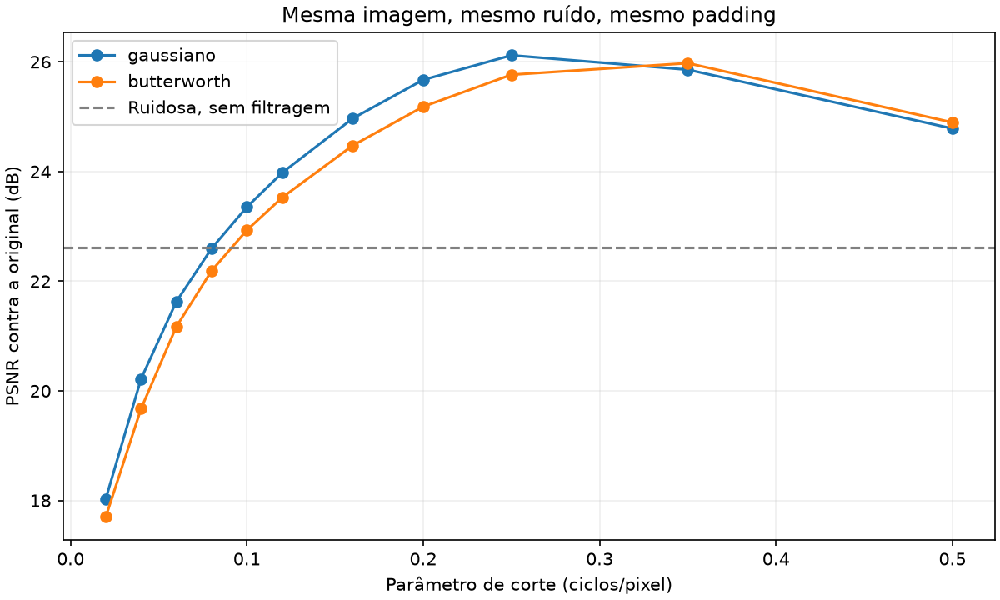

In [3]:
cabecalho = "| Filtro | Corte (ciclos/pixel) | PSNR (dB) | Ganho (dB) |\n|---|---:|---:|---:|\n"
linhas = [f"| {r['filtro']} | {r['corte']:.2f} | {r['psnr_db']:.4f} | {r['ganho_db']:+.4f} |" for r in tabela]
display(Markdown(cabecalho + "\n".join(linhas)))
display(Image(filename=str(SAIDA / "psnr_por_corte.png")))


## 4. Imagens e recorte idêntico para examinar os contornos

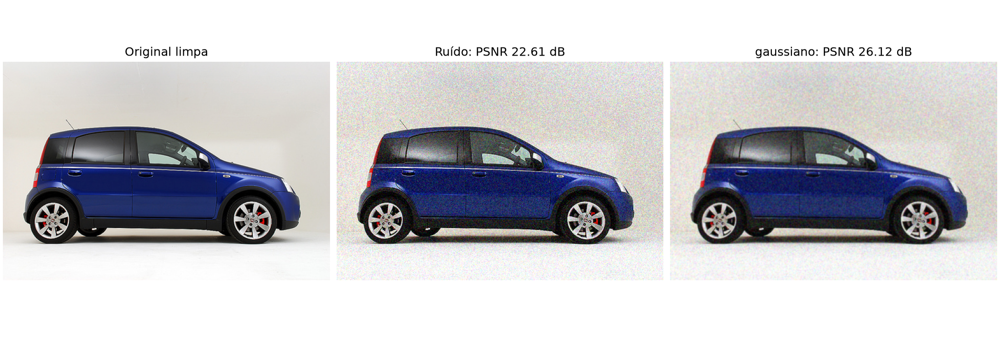

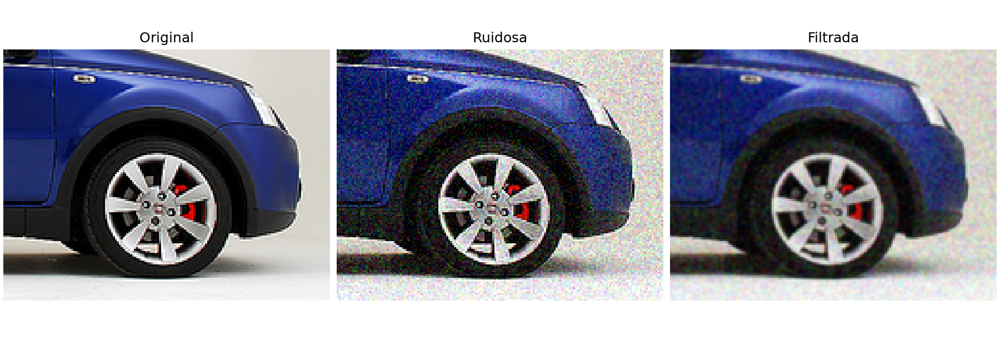

In [4]:
display(Image(filename=str(SAIDA / "comparacao_imagens.png")))
display(Image(filename=str(SAIDA / "recorte_contornos.png")))

## 5. Espectros antes/depois e máscara

Mostramos log(1 + amplitude média dos canais), com a mesma escala antes e depois. O centro é a frequência zero. Frequências radiais maiores ficam atenuadas pelo passa-baixa. Estes espectros correspondem à imagem com padding; o produto complexo é levado à inversa e recortado para 500 × 335.


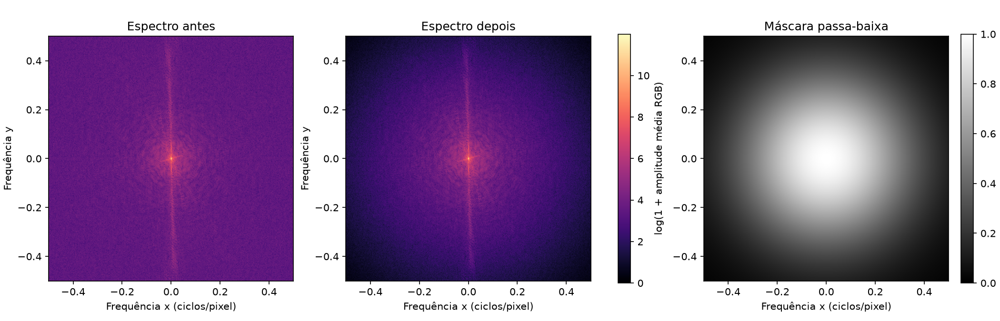

Maior resíduo imaginário da IFFT: 4.805630676128216e-16


In [5]:
display(Image(filename=str(SAIDA / "espectros_mascara.png")))
print("Maior resíduo imaginário da IFFT:", manifesto["residuo_imaginario_max"])

## 6. Discussão e limites

O maior PSNR da grade é uma escolha feita **com acesso à imagem limpa nesta imagem e seed**, apropriada para o experimento controlado. Não demonstra generalização e não é uma seleção cega de parâmetros. Cortes baixos tendem a apagar contornos; altos deixam mais ruído. Rodas, janelas e reflexos são regiões importantes para a inspeção visual. As duas famílias têm respostas diferentes mesmo com o mesmo corte.

A redução do erro de restauração deve ser comparada posteriormente com os mapas e contornos de Gustavo: não garante melhor Watershed/SLIC. A imagem não tem máscara de segmentação declarada; não usamos uma caixa de detecção como máscara de referência.


In [6]:
e = manifesto["escolha"]
display(Markdown(f"Nesta execução, **{e['filtro']}**, corte **{e['corte']:.2f} ciclos/pixel**, atingiu **{e['psnr_db']:.4f} dB**, ganho de **{e['ganho_db']:.4f} dB** sobre a ruidosa."))
dados = np.load(SAIDA / "entradas_segmentacao.npz")
for nome in dados.files:
    print(nome, dados[nome].shape, dados[nome].dtype, dados[nome].min(), dados[nome].max())
assert all(dados[n].shape == dados["original_rgb"].shape for n in dados.files)


Nesta execução, **gaussiano**, corte **0.25 ciclos/pixel**, atingiu **26.1186 dB**, ganho de **3.5053 dB** sobre a ruidosa.

original_rgb (335, 500, 3) float64 0.0 1.0


ruidosa_rgb (335, 500, 3) float64 0.0 1.0


filtrada_rgb (335, 500, 3) float64 0.0 1.0


## 7. Entrega para Gustavo e reprodução

`resultados/frequencia/entradas_segmentacao.npz` contém `original_rgb`, `ruidosa_rgb` e `filtrada_rgb` em float64 [0,1], mesmas dimensões. Usar esses arrays, não as cópias PNG arredondadas. Parâmetros, versões e métricas estão em `parametros.json`; a tabela completa está em `comparacao_filtros.csv`.

Se o segmentador precisar de cinza, aplicar a mesma conversão manual às três condições, sem trocar as imagens ou gerar novo ruído. Não reutilizar os espectros como entrada espacial.

Para reproduzir: instalar `requirements.txt`, obter a imagem com `python scripts/baixar_imagem_voc2012.py` e executar este notebook do início ao fim. Testes matemáticos: `python -m unittest discover -s tests -v`.

Referências: enunciado e material de filtragem no domínio da frequência da disciplina; [documentação NumPy FFT](https://numpy.org/doc/stable/reference/routines.fft.html); [VOC2012 oficial](https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/voc2012/). O código desta frente foi escrito para este projeto.


# Parte 1 — Watershed e SLIC

Os parâmetros numéricos são os mesmos entre condições. O limiar do Watershed é recalculado pelo mesmo percentil em cada imagem. As métricas de contorno medem estabilidade em relação à segmentação da original pelo mesmo método, sem gabarito humano.


In [7]:
# Compartilha a imagem e as entradas efetivamente produzidas acima.
ENTRADAS = SAIDA
RESULTADOS = SAIDA.parent
# O experimento da frequência usa backend Agg para salvar figuras.
# A segmentação precisa do backend inline para embutir as figuras na entrega.
get_ipython().run_line_magic("matplotlib", "inline")


## 1. Implementar e validar Watershed

**Ideia:** a imagem vira um relevo. A altura de cada pixel é a magnitude do gradiente de Sobel, alta nas bordas e baixa dentro das regiões. A água sobe a partir de **marcadores** (fontes) e cada bacia cresce até encontrar outra; o encontro das bacias é o contorno.

**Etapas** (`src/segmentacao.py`):
1. `para_cinza`: o relevo precisa de um valor por pixel.
2. `gradiente_sobel`: altura do relevo, sem normalizar, para manter a mesma escala nas imagens original, ruidosa e filtrada.
3. `marcadores`: regiões planas (gradiente ≤ limiar) com uma área mínima. Sem esse filtro, cada mínimo local vira uma região (supersegmentação).
4. `watershed`: inundação por fila de prioridade, adaptada do exemplo da aula. O pixel mais baixo sai primeiro e passa o rótulo aos vizinhos.
5. `contornos`: pixels onde o rótulo muda.

`segmentar_watershed` junta as etapas. Os parâmetros são **relativos à própria imagem**, porque o enunciado avisa que o professor pode testar qualquer imagem na apresentação:
- `PERCENTIL = 75`: o limiar é o percentil 75 do gradiente, ou seja, os 75% de pixels mais planos podem virar marcador. Um limiar fixo (testamos 0,1) funcionou no carro, mas com ruído σ = 0,05 deixou só 2 marcadores e, em outras imagens do material da aula, nenhum.
- `FRAC_AREA = 0.001`: a região plana precisa ter pelo menos 0,1% dos pixels da imagem (168 px no carro), seja a imagem pequena ou grande.

Validação em entradas pequenas de resposta conhecida: `tests/test_segmentacao.py`.

In [ ]:
import subprocess

# 1) Mostra qual pacote "tests" o Python encontra hoje (esperado: um de /usr/local/lib/..., não o nosso)
print(subprocess.run([sys.executable, "-c", "import tests; print(tests)"],
                     capture_output=True, text=True, cwd=ROOT).stdout)

# 2) Aplica a correção no clone: cria o tests/__init__.py vazio
(ROOT / "tests" / "__init__.py").touch()

# 3) Confere de novo: agora deve apontar para /content/trabalho-m2.2-pdi/tests
print(subprocess.run([sys.executable, "-c", "import tests; print(tests)"],
                     capture_output=True, text=True, cwd=ROOT).stdout)

# 4) Roda os testes
r = subprocess.run([sys.executable, "-m", "unittest", "tests.test_segmentacao"],
                   capture_output=True, text=True, cwd=ROOT)
print(r.stderr)
r.check_returncode()

............
----------------------------------------------------------------------
Ran 12 tests in 0.180s

OK



Marcadores: 20 | Regiões: 20


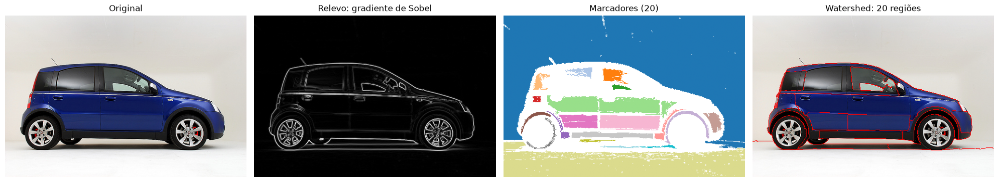

In [9]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from src.segmentacao import segmentar_watershed, contornos

PERCENTIL = 75      # limiar = percentil do gradiente
FRAC_AREA = 0.001   # área mínima do marcador = 0,1% dos pixels

with Image.open(CAMINHO_IMAGEM) as entrada:
    original_rgb = np.asarray(entrada.convert("RGB"), dtype=np.float64) / 255.0

def sobrepor(rgb, rotulos):
    saida = rgb.copy()
    saida[contornos(rotulos)] = [1, 0, 0]
    return saida

grad, marcas, rot_ws = segmentar_watershed(original_rgb, PERCENTIL, FRAC_AREA)
print("Marcadores:", marcas.max(), "| Regiões:", len(np.unique(rot_ws)))

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].imshow(original_rgb); ax[0].set_title("Original")
ax[1].imshow(grad, cmap="gray"); ax[1].set_title("Relevo: gradiente de Sobel")
ax[2].imshow(np.ma.masked_equal(marcas, 0), cmap="tab20"); ax[2].set_title(f"Marcadores ({marcas.max()})")
ax[3].imshow(sobrepor(original_rgb, rot_ws)); ax[3].set_title(f"Watershed: {len(np.unique(rot_ws))} regiões")
for a in ax: a.axis("off")
plt.tight_layout()
(RESULTADOS / "segmentacao").mkdir(parents=True, exist_ok=True)
plt.savefig(RESULTADOS / "segmentacao" / "watershed_original.png", dpi=120, bbox_inches="tight")
plt.show()

### Por que os marcadores importam

Sem área mínima (1 pixel basta), toda pequena região plana vira uma fonte de água, e o resultado é a **supersegmentação**, o principal defeito do Watershed. A figura compara as duas configurações com o mesmo percentil.

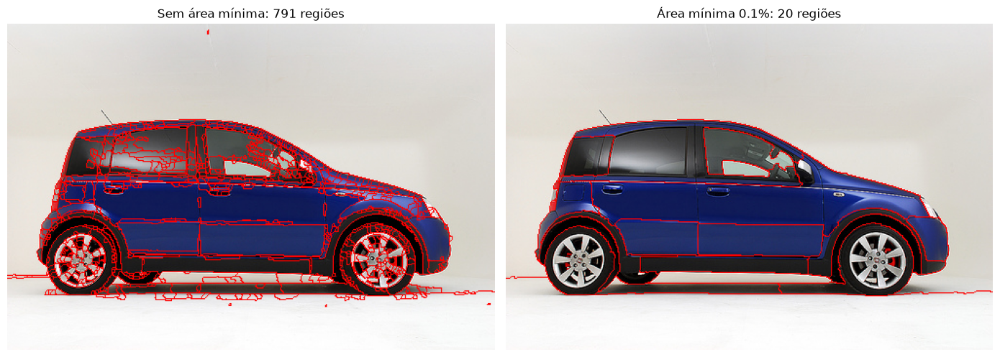

In [10]:
_, marcas_1, rot_1 = segmentar_watershed(original_rgb, PERCENTIL, frac_area=0)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(sobrepor(original_rgb, rot_1)); ax[0].set_title(f"Sem área mínima: {marcas_1.max()} regiões")
ax[1].imshow(sobrepor(original_rgb, rot_ws)); ax[1].set_title(f"Área mínima {FRAC_AREA:.1%}: {marcas.max()} regiões")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "segmentacao" / "watershed_supersegmentacao.png", dpi=120, bbox_inches="tight")
plt.show()

## 2. Implementar e validar SLIC

**Ideia:** um k-means local. Os centros começam numa grade de passo $S = \sqrt{N/K}$ e cada pixel se junta ao centro mais próximo **em cor e em posição**, procurando só numa janela $2S \times 2S$ em volta de cada centro:

$$D = \sqrt{d_c^2 + \left(\frac{m}{S}\right)^2 d_s^2}$$

Depois cada centro vai para a média de posição e cor dos seus pixels, e o processo se repete (10 iterações, como na aula).

- `N_SUPERPIXELS = 200`: quantidade aproximada de regiões (K).
- `M = 20`: compacidade. Com $m$ grande a posição domina e os superpixels viram blocos regulares; com $m$ pequeno a cor domina e os contornos seguem as bordas, mas ficam irregulares. As cores ficam na escala 0–255, como no exemplo da aula; 20 é o meio-termo visual entre 5 e 40 (figura abaixo).

**Diferenças em relação à versão da aula:**
1. Cada janela é calculada de uma vez com NumPy, e não pixel a pixel. O algoritmo é o mesmo, mas leva menos de 1 s no carro.
2. `unir_fragmentos`: passo final do SLIC original (Achanta et al., 2012), que não está no exemplo da aula. O k-means não obriga um rótulo a ser uma peça só: no carro, 216 rótulos viravam até 3.874 pedaços desconexos, o que falsearia o número de regiões. Fragmentos com menos de $S^2/4$ pixels são unidos ao vizinho.

**Watershed × SLIC, na ideia:** o Watershed decide o número de regiões pelo conteúdo da imagem (quantos vales planos existem); o SLIC recebe o número de regiões como parâmetro e divide a imagem em pedaços de tamanho parecido. Por isso o SLIC é uma *pré-segmentação* (superpixels), não uma separação de objetos.

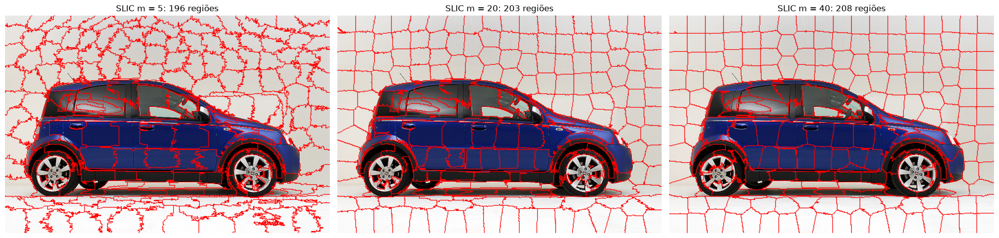

SLIC escolhido (m = 20): 203 regiões


In [11]:
from src.segmentacao import slic

N_SUPERPIXELS = 200
M = 20

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, m in zip(ax, (5, M, 40)):
    rot = slic(original_rgb, N_SUPERPIXELS, m)
    if m == M:
        rot_slic = rot
    a.imshow(sobrepor(original_rgb, rot)); a.set_title(f"SLIC m = {m}: {rot.max()} regiões"); a.axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "segmentacao" / "slic_compacidade.png", dpi=120, bbox_inches="tight")
plt.show()
print("SLIC escolhido (m = %d): %d regiões" % (M, rot_slic.max()))

## 3. Executar nas imagens original, ruidosa e filtrada

Os dois métodos rodam com **os mesmos parâmetros** nas três imagens (`PERCENTIL`, `FRAC_AREA`, `N_SUPERPIXELS`, `M` das seções 1 e 2). Assim, a diferença entre os resultados vem só da imagem.

As três imagens vêm da filtragem da Born, em `resultados/frequencia/entradas_segmentacao.npz`: ruído gaussiano σ = 0,08 com seed 42 e passa-baixa gaussiano com corte 0,25 ciclos/pixel, escolhido pelo maior PSNR (parâmetros em `parametros.json`). Usamos os arrays float64 do `.npz`, e não os PNGs, que são arredondados para 8 bits. Não geramos ruído novo, para que segmentação e PSNR falem das mesmas imagens.

In [12]:
import json

# Para outra imagem: python scripts/experimento_frequencia.py --imagem CAMINHO --destino resultados/teste
dados = np.load(ENTRADAS / "entradas_segmentacao.npz")
parametros = json.loads((ENTRADAS / "parametros.json").read_text(encoding="utf-8"))
assert dados["original_rgb"].shape == original_rgb.shape and np.allclose(dados["original_rgb"], original_rgb), \
    "As entradas da Born são de outra imagem: gere-as para CAMINHO_IMAGEM com o comando acima."
ruidosa_rgb, filtrada_rgb = dados["ruidosa_rgb"], dados["filtrada_rgb"]
e = parametros["escolha"]
print(f"Ruído σ = {parametros['sigma']}, seed {parametros['seed']} | filtro {e['filtro']}, corte {e['corte']} ciclos/pixel")
print(f"PSNR ruidosa {parametros['psnr_ruidosa_db']:.2f} dB -> filtrada {e['psnr_db']:.2f} dB")

Ruído σ = 0.08, seed 42 | filtro gaussiano, corte 0.25 ciclos/pixel
PSNR ruidosa 22.61 dB -> filtrada 26.12 dB


Original  | Watershed   20 regiões (1.1 s) | SLIC  203 regiões (0.9 s)


Ruidosa   | Watershed    9 regiões (1.2 s) | SLIC  148 regiões (1.0 s)


Filtrada  | Watershed   11 regiões (1.3 s) | SLIC  206 regiões (1.0 s)


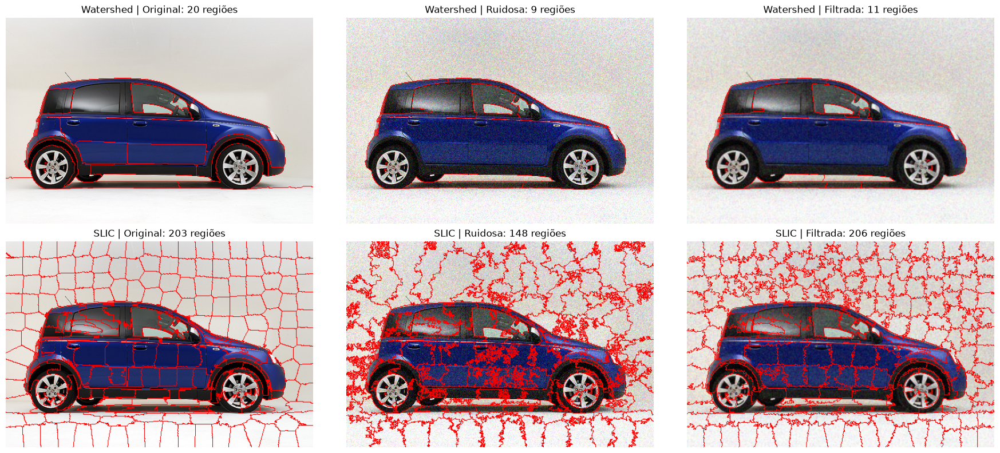

In [13]:
import time

IMAGENS = {"Original": original_rgb, "Ruidosa": ruidosa_rgb, "Filtrada": filtrada_rgb}
METODOS = ("Watershed", "SLIC")
segs = {}
for nome, img in IMAGENS.items():
    t0 = time.perf_counter()
    ws = segmentar_watershed(img, PERCENTIL, FRAC_AREA)[2]
    t1 = time.perf_counter()
    sl = slic(img, N_SUPERPIXELS, M)
    t2 = time.perf_counter()
    segs[nome] = {"Watershed": ws, "SLIC": sl}
    print(f"{nome:9s} | Watershed {ws.max():4d} regiões ({t1 - t0:.1f} s) | SLIC {sl.max():4d} regiões ({t2 - t1:.1f} s)")

fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for j, nome in enumerate(IMAGENS):
    for i, metodo in enumerate(METODOS):
        rot = segs[nome][metodo]
        ax[i, j].imshow(sobrepor(IMAGENS[nome], rot))
        ax[i, j].set_title(f"{metodo} | {nome}: {rot.max()} regiões")
        ax[i, j].axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "segmentacao" / "comparacao_regioes.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Comparar regiões e sobrepor contornos

**Não existe gabarito** para esta imagem (`segmented=0` no XML do VOC, ver `data/README.md`). Então a referência de cada método é **a segmentação que ele mesmo faz na original limpa**. A pergunta respondida é: *quanto o ruído desloca os contornos, e quanto o filtro recupera?* Isso mede estabilidade, não acerto em relação a uma segmentação humana.

Métricas (`comparar_contornos`, mesma ideia do benchmark BSDS, Martin et al., 2004), com tolerância de 2 px, porque um contorno deslocado em 1 px ainda é o mesmo contorno:
- **Número de regiões**, pedido pelo enunciado.
- **Precisão:** fração do contorno obtido que também existe na referência. Baixa = **bordas falsas**, criadas pelo ruído.
- **Revocação:** fração do contorno da referência que foi reencontrado. Baixa = **bordas perdidas**.
- **F1:** média harmônica das duas, para resumir num número só.

Na figura de zoom, **amarelo** = contorno que coincide com a referência, **vermelho** = borda falsa ou deslocada (derruba a precisão), **verde** = borda da referência que sumiu (derruba a revocação).

As cores do zoom usam coincidência exata de pixels; a métrica numérica admite tolerância de 2 px. Uma borda deslocada pode aparecer em vermelho/verde e ainda ser aceita pela métrica.

In [14]:
import csv
from src.segmentacao import comparar_contornos

TOLERANCIA = 2  # px

linhas = []
print(f"{'Método':10s} {'Imagem':9s} {'Regiões':>7s} {'Precisão':>9s} {'Revocação':>10s} {'F1':>5s}")
for metodo in METODOS:
    referencia = segs["Original"][metodo]
    for nome in IMAGENS:
        rot = segs[nome][metodo]
        p, r, f = comparar_contornos(rot, referencia, TOLERANCIA)
        linhas.append((metodo, nome, int(rot.max()), round(p, 3), round(r, 3), round(f, 3)))
        print(f"{metodo:10s} {nome:9s} {rot.max():7d} {p:9.2f} {r:10.2f} {f:5.2f}")

# Tabela para a Born juntar com PSNR/SSIM no notebook final.
with open(RESULTADOS / "segmentacao" / "tabela_segmentacao.csv", "w", newline="", encoding="utf-8") as arq:
    escritor = csv.writer(arq)
    escritor.writerow(["metodo", "imagem", "regioes", "precisao", "revocacao", "f1"])
    escritor.writerows(linhas)

Método     Imagem    Regiões  Precisão  Revocação    F1
Watershed  Original       20      1.00       1.00  1.00
Watershed  Ruidosa         9      0.89       0.55  0.68
Watershed  Filtrada       11      0.89       0.56  0.69
SLIC       Original      203      1.00       1.00  1.00
SLIC       Ruidosa       148      0.47       0.70  0.56
SLIC       Filtrada      206      0.66       0.83  0.74


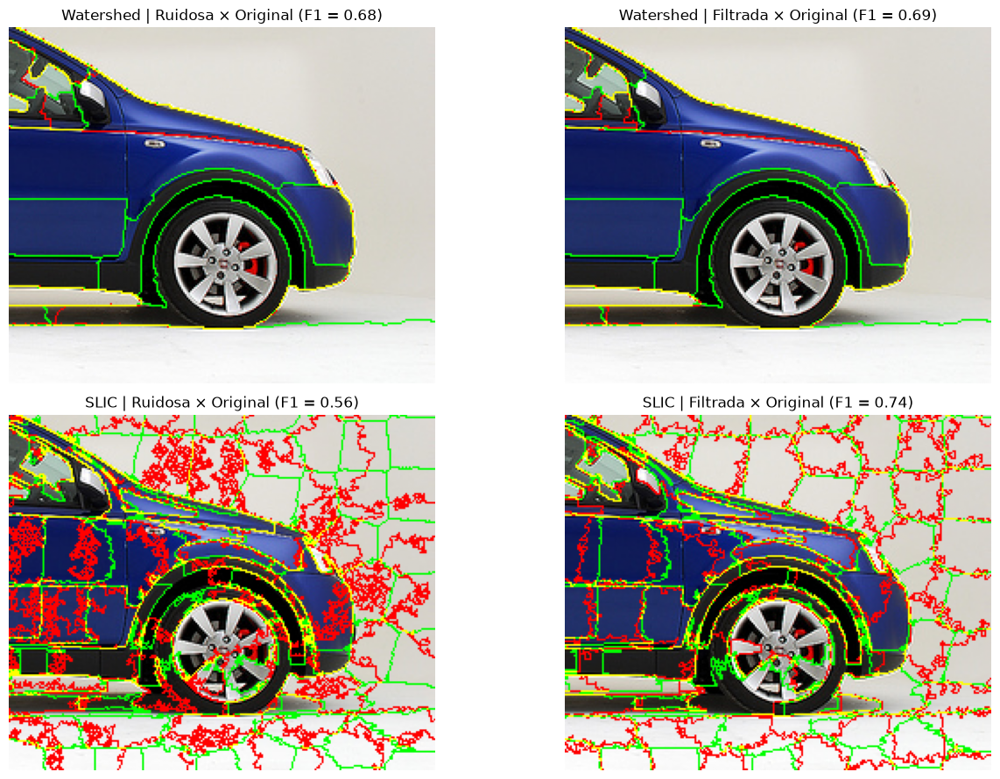

In [15]:
def sobrepor_referencia(rgb, rotulos, referencia):
    saida = rgb.copy()
    c, ref = contornos(rotulos), contornos(referencia)
    saida[ref & ~c] = [0, 1, 0]  # verde: borda perdida
    saida[c & ~ref] = [1, 0, 0]  # vermelho: borda falsa ou deslocada
    saida[c & ref] = [1, 1, 0]   # amarelo: coincide com a referência
    return saida

ZOOM = (slice(110, 310), slice(260, 500))  # frente do carro: roda, capô e para-brisa
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for i, metodo in enumerate(METODOS):
    for j, nome in enumerate(("Ruidosa", "Filtrada")):
        _, _, f = comparar_contornos(segs[nome][metodo], segs["Original"][metodo], TOLERANCIA)
        quadro = sobrepor_referencia(original_rgb, segs[nome][metodo], segs["Original"][metodo])
        ax[i, j].imshow(quadro[ZOOM])
        ax[i, j].set_title(f"{metodo} | {nome} × Original (F1 = {f:.2f})")
        ax[i, j].axis("off")
plt.tight_layout()
plt.savefig(RESULTADOS / "segmentacao" / "comparacao_contornos_zoom.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Registrar metodologia, parâmetros e limitações

**Metodologia da comparação visual:**
1. Mesma imagem de entrada (`2009_003974.jpg`) e mesmos parâmetros nas três versões: original, ruidosa e filtrada.
2. Contornos em vermelho sobre a imagem (seção 3), e o número de regiões no título.
3. Referência de cada método = sua segmentação da original limpa. No zoom, a cor diz se a borda coincide, é falsa ou foi perdida (seção 4).
4. Números na tabela (`resultados/segmentacao/tabela_segmentacao.csv`), juntados com PSNR no notebook final (SSIM é opcional e não foi utilizado).

**Parâmetros:**

| Método | Parâmetro | Valor | Por quê |
|---|---|---|---|
| Watershed | limiar dos marcadores | percentil 75 do gradiente | relativo à imagem; um valor fixo falhou com ruído e em outras imagens |
| Watershed | área mínima do marcador | 0,1% dos pixels | evita a supersegmentação (791 regiões sem ela) |
| SLIC | superpixels (K) | 200 | detalhe suficiente sem ficar lento |
| SLIC | compacidade (m) | 20 | meio-termo entre seguir bordas (m = 5) e virar grade (m = 40) |
| SLIC | iterações | 10 | como na aula |
| Métrica | tolerância de contorno | 2 px | um contorno deslocado em 1–2 px ainda é o mesmo |

**O que a tabela mostra** (entradas da Born: ruído σ = 0,08; filtro gaussiano com corte 0,25 ciclos/pixel):
- **Watershed perde bordas.** As regiões caem de 20 para 9 e a revocação para 0,55, mas a precisão continua alta (0,89). O ruído quebra as regiões planas em pedaços menores que a área mínima, sobram menos marcadores e bacias vizinhas se fundem. As bordas que sobram são as fortes.
- **SLIC inventa bordas.** A precisão cai para 0,47: os contornos ficam serrilhados e caem fora da referência. Com esse ruído forte, o número de regiões também cai (203 → 148): 72 dos 216 superpixels ficam pulverizados em pedaços menores que $S^2/4$ e são absorvidos pelos vizinhos (na original, 21). Com ruído moderado (σ = 0,05, testado durante o desenvolvimento) o SLIC mantinha cerca de 200 regiões; ou seja, contar regiões subestima o efeito do ruído no SLIC.
- **O filtro recupera o SLIC, quase nada do Watershed.** SLIC: F1 0,56 → 0,74 e 206 regiões. Watershed: F1 0,68 → 0,69 e 11 regiões. O corte escolhido pelo maior PSNR é suave e deixa ruído suficiente para continuar quebrando as regiões planas que viram marcadores.
- **PSNR × segmentação:** o filtro ganha 3,5 dB de PSNR (22,6 → 26,1 dB), mas o F1 do Watershed sobe só 0,01. PSNR melhor não garante segmentação melhor; por isso medimos os contornos.

**Limitações:**
- Sem gabarito humano, a métrica mede **estabilidade frente ao ruído**, e não acerto. Uma borda que o método erra na original também é "referência".
- No fundo liso, as fronteiras do SLIC são arbitrárias (seguem a grade inicial); qualquer perturbação as desloca, o que penaliza a precisão do SLIC mesmo onde não há objeto.
- Uma imagem só e uma única realização do ruído (seed fixa). Os números servem para comparar os métodos entre si, não como valor geral.
- A métrica não faz o pareamento um-para-um do BSDS (comentado no código).
- Tempo: Python puro nos laços do Watershed e de `unir_fragmentos`; imagens acima de ~1000 px de lado levam vários segundos, e convém reduzi-las.

**Por que não os outros métodos da aula:** o enunciado pede Watershed e SLIC. Os outros servem de contraste:
- **Limiarização (Otsu):** separa só por intensidade e gera regiões desconexas, sem noção de vizinhança; o carro azul, o fundo claro e os reflexos não se separam por um único limiar.
- **k-means puro:** agrupa só por cor; o SLIC é exatamente o k-means com a posição na distância e a busca local, o que gera regiões compactas e conexas.
- **Canny:** dá bordas, não regiões; as bordas não fecham sozinhas e não dá para contar regiões.
- **Crescimento de regiões:** depende de sementes manuais e de um limiar de similaridade; o Watershed com marcadores automáticos resolve as duas coisas pelo relevo do gradiente.

# Síntese da Parte 1

PSNR avalia restauração de intensidades; F1 avalia estabilidade de contornos de cada método. São medidas distintas, sem comparação direta de escala. F1 da original é 1 por definição da referência, não indica segmentação humana perfeita.


In [16]:
import csv
from src.metricas import psnr
from IPython.display import display, Markdown

combinada = []
for metodo, nome, regioes, precisao, revocacao, f1 in linhas:
    score = psnr(original_rgb, IMAGENS[nome])
    combinada.append(dict(metodo=metodo, imagem=nome, psnr_db=score,
                          regioes=regioes, precisao=precisao, revocacao=revocacao, f1=f1))
destino = RESULTADOS / "comparacao_parte1.csv"
with destino.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=combinada[0].keys())
    writer.writeheader(); writer.writerows(combinada)
cabecalho = "| Método | Imagem | PSNR (dB) | Regiões | F1 de estabilidade |\n|---|---|---:|---:|---:|\n"
texto = [f"| {r['metodo']} | {r['imagem']} | {r['psnr_db']:.2f} | {r['regioes']} | {r['f1']:.3f} |" for r in combinada]
display(Markdown(cabecalho + "\n".join(texto)))
print("Tabela integrada:", destino)


| Método | Imagem | PSNR (dB) | Regiões | F1 de estabilidade |
|---|---|---:|---:|---:|
| Watershed | Original | inf | 20 | 1.000 |
| Watershed | Ruidosa | 22.61 | 9 | 0.679 |
| Watershed | Filtrada | 26.12 | 11 | 0.685 |
| SLIC | Original | inf | 203 | 1.000 |
| SLIC | Ruidosa | 22.61 | 148 | 0.561 |
| SLIC | Filtrada | 26.12 | 206 | 0.736 |

Tabela integrada: C:\Users\heloi\OneDrive\Documentos\Faculdade\Processamento de Imagens\trabalho-m2.2-pdi\resultados\comparacao_parte1.csv


# Parte 2 — Morfologia e contagem (João Paulo)

Contagem de componentes conectados nas imagens do enunciado; objetos encostados podem representar mais de uma célula.

In [17]:
from pathlib import Path
import sys

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None:
    raise RuntimeError("Abra o Jupyter dentro da pasta do projeto.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA = ROOT / "data" / "originais"
RESULTADOS = ROOT / "resultados"
SAIDA_CELULAS = RESULTADOS / "celulas"
SAIDA_CELULAS.mkdir(parents=True, exist_ok=True)
print("Projeto:", ROOT.name)

# Configure aqui as entradas ao testar outra imagem.
# objeto_claro: True para objeto claro em fundo escuro; False para objeto escuro em fundo claro.
# sigma = gaussiano leve; raios em pixels do disco do fechamento e da abertura (0 pula a etapa).
IMAGENS = {
    "Imagem 1": dict(arquivo="gap-region-filling.tif", objeto_claro=True, sigma=0, raio_fechamento=2, raio_abertura=2),
    "Imagem 2": dict(arquivo="002f20ad-2ace-499c-9335-c9080bc3e6b5.png", objeto_claro=False, sigma=2, raio_fechamento=2, raio_abertura=4),
}

Projeto: trabalho-m2.2-pdi


Os testes conferem cada operação em entradas pequenas de resposta conhecida: dilatação e erosão contra a definição com elemento assimétrico, abertura removendo partícula, fechamento unindo fragmentos, preenchimento sem vazar pela diagonal, Otsu e rotulagem em 4 e 8 vizinhos.

In [18]:
import os
import subprocess
# NO_COLOR: o Python 3.14 colore a saída do unittest com códigos ANSI.
r = subprocess.run([sys.executable, "-m", "unittest", "tests.test_morfologia"], capture_output=True, text=True,
                   cwd=ROOT, env={**os.environ, "NO_COLOR": "1"})
print(r.stderr)
r.check_returncode()  # depois do print, para o erro dos testes aparecer

.............
----------------------------------------------------------------------
Ran 13 tests in 0.183s

OK



## 1. Carregar as duas imagens exigidas e converter para cinza

As imagens vêm dos links do enunciado (ver `data/README.md`). A conversão para cinza é feita pela função própria `para_cinza` (pesos BT.601). O carregamento aceita cinza 8 e 16 bits, RGB, RGBA e paleta, porque o processamento pode ser testado com qualquer imagem na apresentação.

O histograma mostra onde o Otsu colocou o limiar. A Imagem 1 já é binária (só 0 e 255): o filtro gaussiano só borraria as bordas, por isso `sigma = 0`. A Imagem 2 é um esfregaço de sangue colorido: hemácias roxas em fundo branco, então o objeto é **escuro** e o centro claro de cada hemácia aparece como buraco.

Imagem 1: (512, 512), Otsu = 0.500


Imagem 2: (1200, 1600, 3), Otsu = 0.771


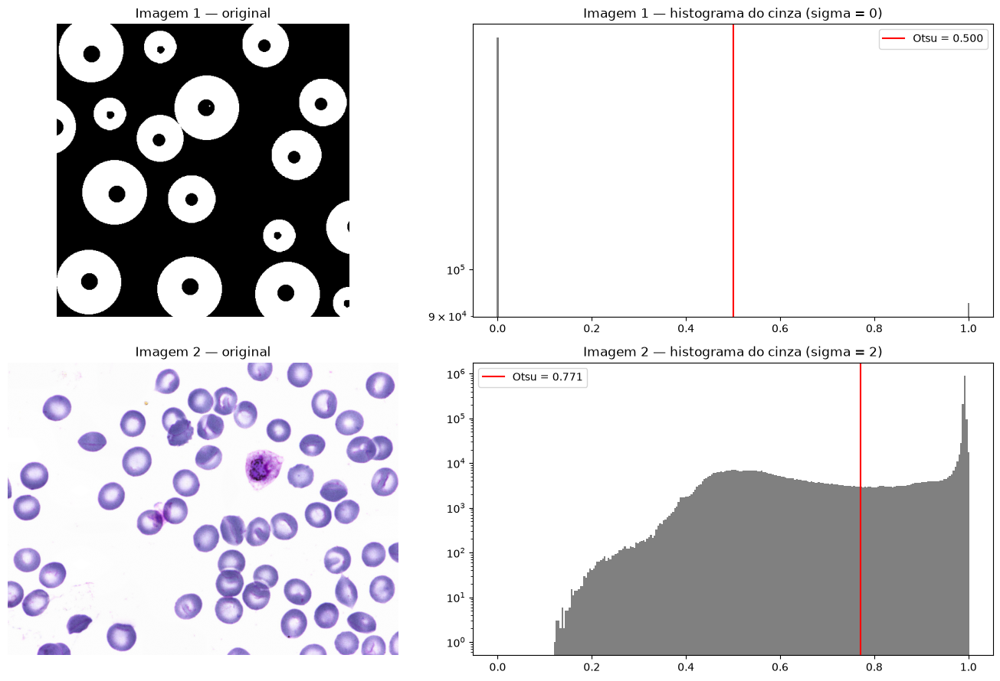

In [19]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from src.segmentacao import para_cinza
from src.morfologia import filtro_gaussiano, histograma, limiar_otsu

def carregar(caminho):
    """Imagem em float [0, 1], cinza ou RGB."""
    with Image.open(caminho) as im:
        if im.mode.startswith("I"):              # cinza 16/32 bits
            a = np.asarray(im, dtype=np.float64)
            return a / a.max() if a.max() > 0 else a
        if im.mode not in ("L", "RGB"):          # RGBA, paleta, 1 bit
            im = im.convert("RGB")
        return np.asarray(im, dtype=np.float64) / 255.0

originais = {nome: carregar(DATA / p["arquivo"]) for nome, p in IMAGENS.items()}

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for i, (nome, img) in enumerate(originais.items()):
    p = IMAGENS[nome]
    suave = filtro_gaussiano(para_cinza(img), p["sigma"])
    t = limiar_otsu(suave)
    print(f"{nome}: {img.shape}, Otsu = {t:.3f}")
    ax[i, 0].imshow(img, cmap="gray"); ax[i, 0].set_title(f"{nome} — original"); ax[i, 0].axis("off")
    ax[i, 1].bar(np.arange(256) / 255, histograma(suave), width=1 / 255, color="gray")
    ax[i, 1].axvline(t, color="red", label=f"Otsu = {t:.3f}")
    ax[i, 1].set_yscale("log"); ax[i, 1].set_title(f"{nome} — histograma do cinza (sigma = {p['sigma']})"); ax[i, 1].legend()
plt.tight_layout()
plt.show()

## 2. Implementar limiarização e analisar falhas

Limiar de Otsu: escolhe o nível que maximiza a variância entre as duas classes. Depois da limiarização aparecem as falhas descritas no enunciado. Em vermelho, os pixels que o preenchimento de buracos vai acrescentar: o centro dos anéis na Imagem 1 e o centro claro das hemácias na Imagem 2. Algumas hemácias têm o centro claro aberto para fora (forma de "C"); como esse buraco toca o fundo, não é buraco para o algoritmo e não é preenchido.

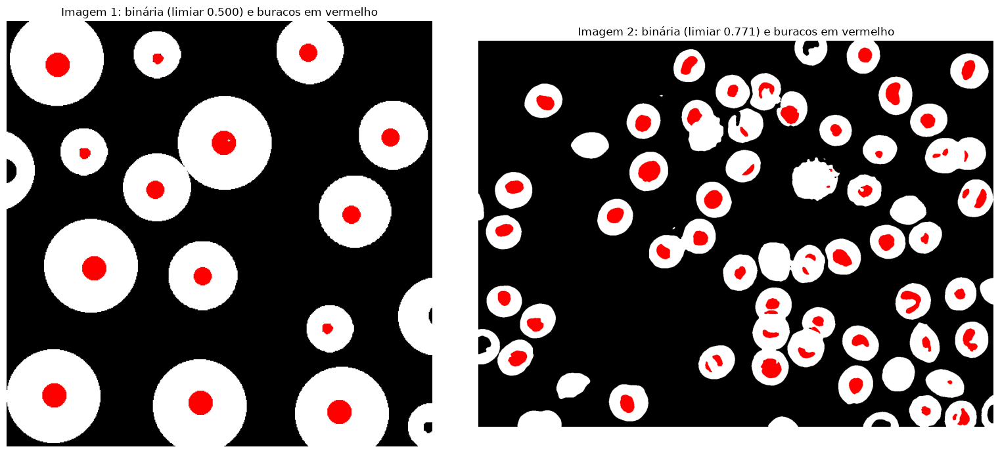

In [20]:
from src.morfologia import segmentar_celulas

etapas = {nome: segmentar_celulas(img, sigma=p["sigma"], objeto_claro=p["objeto_claro"],
                                  raio_fechamento=p["raio_fechamento"], raio_abertura=p["raio_abertura"])
          for (nome, img), p in zip(originais.items(), IMAGENS.values())}

def destacar_buracos(e):
    """Branco = objeto após limiarizar; vermelho = buraco que o preenchimento fecha."""
    rgb = np.zeros(e["binaria"].shape + (3,))
    rgb[e["binaria"]] = 1
    rgb[e["preenchida"] & ~e["fechada"]] = [1, 0, 0]
    return rgb

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, (nome, e) in zip(ax, etapas.items()):
    a.imshow(destacar_buracos(e)); a.axis("off")
    a.set_title(f"{nome}: binária (limiar {e['limiar']:.3f}) e buracos em vermelho")
plt.tight_layout()
plt.savefig(SAIDA_CELULAS / "falhas_limiarizacao.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Implementar fechamento, preenchimento e abertura

Ordem do enunciado, com elemento estruturante em **disco** (isotrópico, combina com núcleos arredondados):

1. **Fechamento** (dilatação seguida de erosão): une fragmentos e fecha frestas menores que o disco, o que pode transformar em buraco interno o centro claro aberto ("C") de algumas hemácias.
2. **Preenchimento de buracos**: inunda o fundo a partir da borda da imagem, com dilatação condicional em 4 vizinhos; o que a água não alcança é buraco. O par 4 (fundo) / 8 (objeto) impede a água de atravessar uma quina diagonal por onde o objeto está conectado.
3. **Abertura** (erosão seguida de dilatação): remove partículas menores que o disco e devolve aos objetos restantes quase o tamanho original.

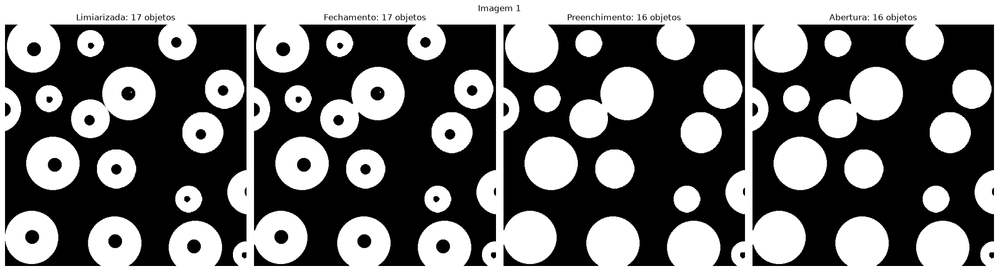

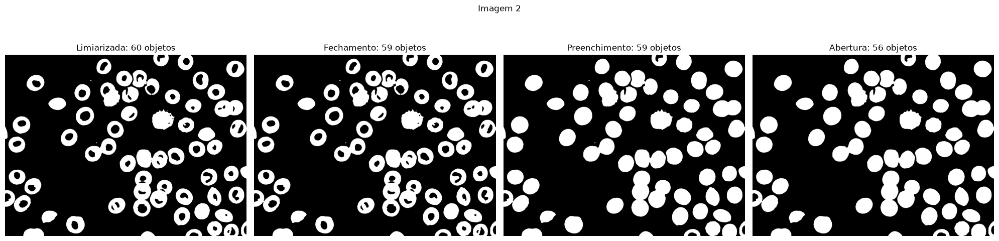

In [21]:
from src.contagem import contar_objetos

NOMES_ETAPAS = {"binaria": "Limiarizada", "fechada": "Fechamento", "preenchida": "Preenchimento", "aberta": "Abertura"}
for nome, e in etapas.items():
    fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
    for a, (chave, titulo) in zip(ax, NOMES_ETAPAS.items()):
        n, _ = contar_objetos(e[chave])
        a.imshow(e[chave], cmap="gray"); a.set_title(f"{titulo}: {n} objetos"); a.axis("off")
    fig.suptitle(nome)
    plt.tight_layout()
    plt.savefig(SAIDA_CELULAS / f"etapas_{nome.lower().replace(' ', '')}.png", dpi=110, bbox_inches="tight")
    plt.show()

## 4. Implementar componentes conectados e comparar contagens por etapa

Contagem própria (`src/contagem.py`): percorre a imagem em ordem de leitura; ao achar um pixel de objeto sem rótulo, abre um rótulo novo e o espalha por busca em largura aos vizinhos de objeto (8-vizinhança). Cada pixel entra na fila uma vez, então o custo é linear. O número de rótulos é o número de objetos.

A tabela mostra a contagem em cada etapa e quantos pixels de objeto existem. Para estimar células fundidas, contamos os objetos finais com mais de 1,5 vez a área mediana. O critério só faz sentido quando as células têm tamanho parecido, como na Imagem 2; na Imagem 1 os anéis têm tamanhos diferentes por construção.

In [22]:
import csv
from src.contagem import areas, comparar_etapas

tabela = []
for nome, e in etapas.items():
    linhas = comparar_etapas({titulo: e[chave] for chave, titulo in NOMES_ETAPAS.items()})
    for l in linhas:
        tabela.append(dict(imagem=nome, **l))
    _, rot = contar_objetos(e["aberta"])
    a = areas(rot)
    grandes = int((a > 1.5 * np.median(a)).sum())
    print(f"{nome}: área mediana {np.median(a):.0f} px; {grandes} objetos com mais de 1,5x a mediana")

print(f"\n{'Imagem':9} {'Etapa':14} {'Objetos':>7} {'Variação':>8} {'Pixels de objeto':>17}")
for l in tabela:
    var = "" if l["variacao"] is None else f"{l['variacao']:+d}"
    print(f"{l['imagem']:9} {l['etapa']:14} {l['objetos']:7d} {var:>8} {l['pixels_objeto']:17d}")
with open(SAIDA_CELULAS / "contagem_etapas.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=tabela[0].keys())
    w.writeheader(); w.writerows(tabela)

Imagem 1: área mediana 5412 px; 6 objetos com mais de 1,5x a mediana


Imagem 2: área mediana 9252 px; 8 objetos com mais de 1,5x a mediana

Imagem    Etapa          Objetos Variação  Pixels de objeto
Imagem 1  Limiarizada         17                      92581
Imagem 1  Fechamento          17       +0             92653
Imagem 1  Preenchimento       16       -1             98963
Imagem 1  Abertura            16       +0             98963
Imagem 2  Limiarizada         60                     466102
Imagem 2  Fechamento          59       -1            466488
Imagem 2  Preenchimento       59       +0            540076
Imagem 2  Abertura            56       -3            539834


## 5. Exibir original, binária, processada e rótulos coloridos

Cada objeto recebe uma cor (matizes espaçados pelo ângulo áureo, então vizinhos na ordem de leitura ficam com cores bem diferentes) e o seu número no centroide. Uma mesma cor pode abranger células encostadas, pois a rotulagem conta componentes conectados.

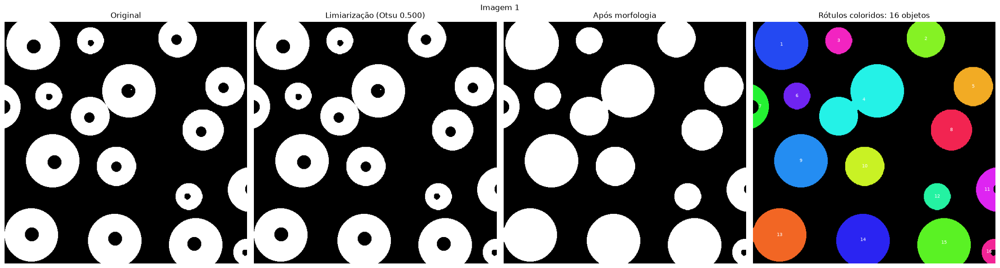

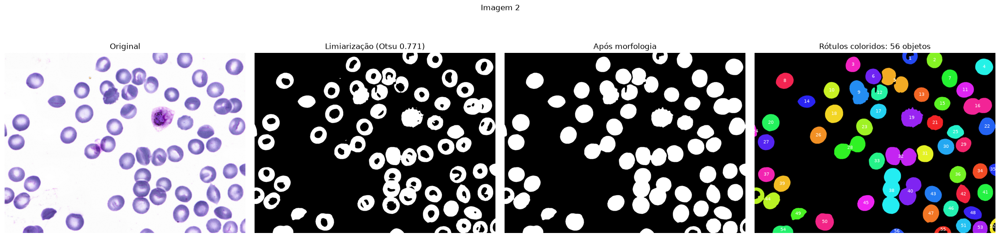

In [23]:
from src.contagem import colorir_rotulos, medidas

for nome, e in etapas.items():
    n, rot = contar_objetos(e["aberta"])
    fig, ax = plt.subplots(1, 4, figsize=(22, 6))
    ax[0].imshow(originais[nome], cmap="gray"); ax[0].set_title("Original")
    ax[1].imshow(e["binaria"], cmap="gray"); ax[1].set_title(f"Limiarização (Otsu {e['limiar']:.3f})")
    ax[2].imshow(e["aberta"], cmap="gray"); ax[2].set_title("Após morfologia")
    ax[3].imshow(colorir_rotulos(rot)); ax[3].set_title(f"Rótulos coloridos: {n} objetos")
    for obj in medidas(rot):
        y, x = obj["centroide"]
        ax[3].text(x, y, obj["rotulo"], color="white", fontsize=7, ha="center", va="center")
    for a in ax: a.axis("off")
    fig.suptitle(nome)
    plt.tight_layout()
    plt.savefig(SAIDA_CELULAS / f"resultado_{nome.lower().replace(' ', '')}.png", dpi=110, bbox_inches="tight")
    plt.show()

## 6. Parâmetros, resultados e limitações

| Parâmetro | Imagem 1 | Imagem 2 | Por quê |
|---|---|---|---|
| Objeto | claro | escuro | anéis brancos em fundo preto; hemácias roxas em fundo branco |
| Gaussiano (sigma) | 0 | 2 | a Imagem 1 já é binária; na 2 suaviza a textura dentro das hemácias |
| Limiar | Otsu | Otsu | dois grupos bem separados no histograma |
| Fechamento | disco r = 2 | disco r = 2 | fecha frestas pequenas; r = 6 já fundia hemácias (60 → 51 objetos) |
| Abertura | disco r = 2 | disco r = 4 | remove partículas; na Imagem 2 há resíduos de corante |
| Conectividade | 8 (objeto), 4 (fundo) | 8 (objeto), 4 (fundo) | par complementar: o fundo não vaza por quinas diagonais |

**Imagem 1.** São 17 componentes depois da limiarização. Um deles é um ponto de 5 pixels **dentro do buraco** de um anel: conta como objeto falso até o preenchimento, que o incorpora ao anel. Por isso a contagem cai de 17 para 16 só no gap-filling, que é exatamente a comparação pedida no enunciado. Os anéis cortados pela borda da imagem continuam ocos, porque o seu buraco toca a borda e, para o algoritmo, é fundo. Dois anéis que se tocam contam como um único objeto: a morfologia sozinha não separa objetos encostados.

**Imagem 2.** O preenchimento acrescenta dezenas de milhares de pixels (o centro claro das hemácias), mas quase não muda a contagem: um anel já era contado como um objeto. O ganho do gap-filling aqui está na forma e na área de cada célula, não no número. O erro principal da contagem são as **hemácias encostadas**, que viram um objeto só: objetos com mais de 1,5 vez a área mediana são candidatos a esses aglomerados; o critério é heurístico. Fechamento maior pioraria isso. Separá-las exigiria Watershed na transformada de distância, que o enunciado deixa fora desta parte. O objeto maior e escuro no centro também entra na contagem; seu tipo celular não é identificado pelo algoritmo.

**Limitações.** Os raios foram escolhidos por inspeção visual nestas duas imagens; não há contagem manual de referência para medir o erro. Células cortadas pela borda contam como objetos inteiros.

# Conclusões

O filtro Gaussiano escolhido elevou o PSNR de 22,61 para 26,12 dB. O F1 de estabilidade de contornos aumentou de 0,561 para 0,736 no SLIC e de 0,679 para 0,685 no Watershed. Melhor restauração não implica melhora equivalente em todos os segmentadores.

Na Parte 2, as contagens passaram de 17 para 16 objetos na Imagem 1 e de 60 para 56 na Imagem 2. O preenchimento isolado mudou a contagem apenas na primeira; na segunda corrigiu principalmente áreas e formas. Não há contagem humana de referência e componentes de células encostadas permanecem unidos.

Os resultados são específicos das imagens, parâmetros e seed utilizados. As implementações próprias e as intermediárias permitem examinar tanto os ganhos quanto as falhas dos métodos.
